# Gillespie simulation of a birth–death CTMC

$n \to n+1$: $\lambda$

$n \to n-1$: $\mu n$

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.7.1+cu126 | device: cuda


In [2]:
birth, death, t_end = 8.0, 1.0, 2000.0

def gillespie_birth_death(birth, death, t_end, n0=0):
    t, n = 0.0, n0
    times, states = [t], [n]
    while t < t_end:
        rates = torch.tensor([birth, death*n], device=device)
        total = rates.sum()
        wait = -torch.log(torch.rand((), device=device)) / total
        t += float(wait)
        if t > t_end:
            break
        n += 1 if torch.rand((), device=device) * total < rates[0] else -1
        times.append(t); states.append(n)
    times.append(t_end); states.append(n)
    return np.array(times), np.array(states)

times, states = gillespie_birth_death(birth, death, t_end)
weights = np.diff(times)
occupancy = np.bincount(states[:-1], weights=weights, minlength=25) / t_end
ks = np.arange(25)
from math import factorial
exact = np.array([np.exp(-birth/death)*(birth/death)**k/factorial(k) for k in ks])
print('time-average n:', np.sum(states[:-1]*weights)/t_end, '| theory:', birth/death)

time-average n: 8.069471882248802 | theory: 8.0


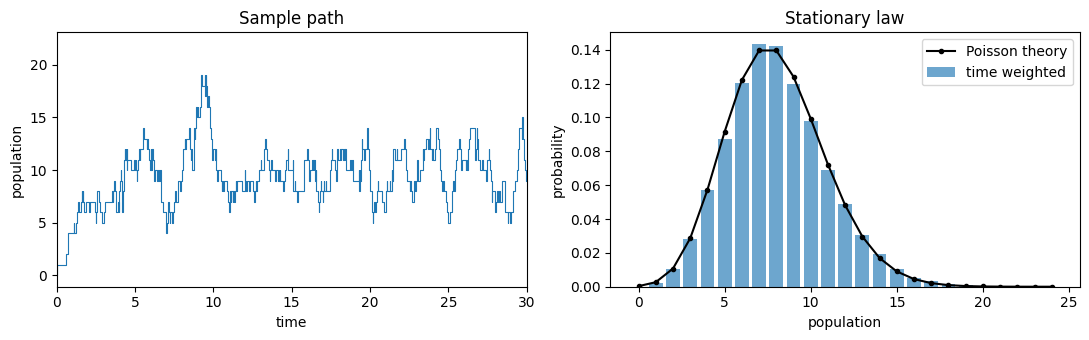

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].step(times, states, where='post', lw=.8)
ax[0].set(xlim=(0, 30), xlabel='time', ylabel='population', title='Sample path')
ax[1].bar(ks, occupancy[:25], alpha=.65, label='time weighted')
ax[1].plot(ks, exact, 'ko-', ms=3, label='Poisson theory')
ax[1].set(xlabel='population', ylabel='probability', title='Stationary law')
ax[1].legend(); plt.tight_layout(); plt.show()